# 🏈 NFL Data Analysis — Part 4: Actions & Outcomes — How to Play Better

The first three notebooks explained *what* happens in a game. This one asks the coaching question:
**which decisions actually lead to better outcomes — and how should a team evolve its play-calling?**

We'll pair each *action* (a choice the offense or defense makes) with its *outcome* and turn the
numbers into concrete "do more of this, less of that" recommendations.

---
## What you'll learn
- A proper way to measure play **success** (not just raw yards)
- Which formations, personnel, and play-action choices produce the best results
- How different defensive coverages hold up — and which ones get beaten
- A data-driven "playbook" of recommendations to play better

> ⚠️ **Dataset note:** every play here is a QB dropback (a passing play), so all recommendations
> are about the *passing game and its defense*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='deep')

games = pd.read_csv('../data/games.csv')
plays = pd.read_csv('../data/plays.csv')
plays = plays.merge(games[['gameId', 'week']], on='gameId', how='left')
print(f'{len(plays):,} passing plays loaded')

/home/armand/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


8,557 passing plays loaded


---
## 1 — First, a better scoreboard: "Success Rate"

> **Coaching basics:** Raw yards can mislead you. Gaining 4 yards on 3rd & 10 is a *failure* (you punt);
> gaining 4 yards on 3rd & 3 is a *success* (you keep the ball). Analysts use **Success Rate**, which
> counts a play as successful if it gains:
> - **≥ 40%** of needed yards on **1st down**
> - **≥ 60%** on **2nd down**
> - **≥ 100%** on **3rd/4th down** (you must convert)
>
> This is the single best yes/no measure of whether a play "worked."

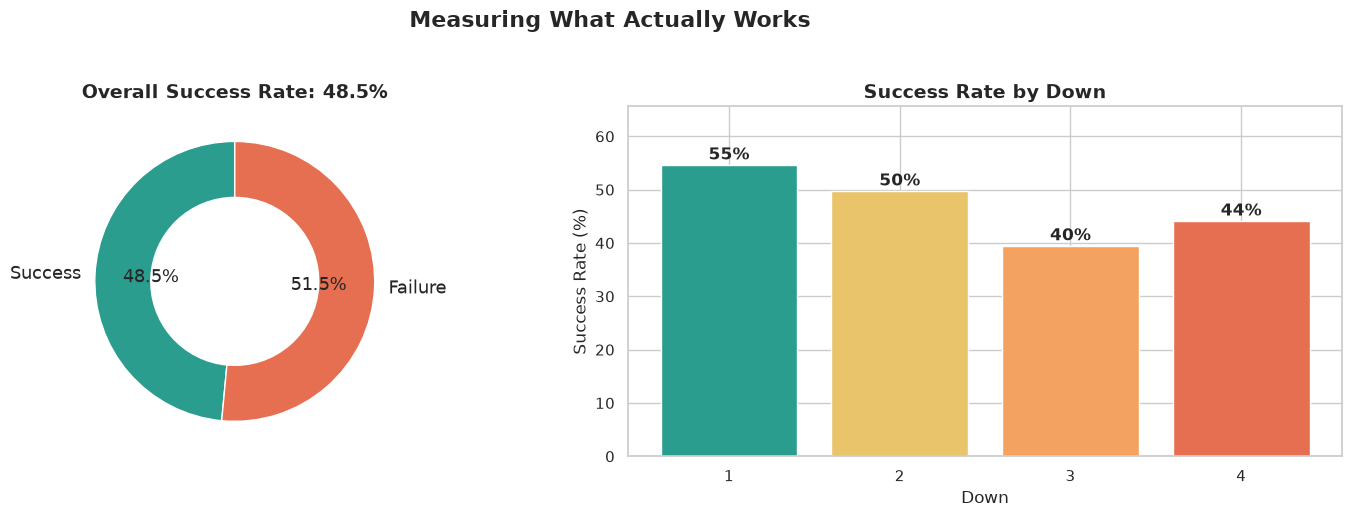

Reading it: a play "succeeds" when it gains enough for the situation. Later downs are harder.


In [2]:
def is_success(row):
    down = row['down']
    gained = row['playResult']
    needed = row['yardsToGo']
    if pd.isna(down) or pd.isna(needed) or needed == 0:
        return np.nan
    if down == 1:
        return gained >= 0.4 * needed
    elif down == 2:
        return gained >= 0.6 * needed
    else:  # 3rd / 4th down
        return gained >= needed

plays['success'] = plays.apply(is_success, axis=1)
plays['is_sack'] = (plays['passResult'] == 'S').astype(int)
plays['is_int'] = (plays['passResult'] == 'IN').astype(int)
plays['is_complete'] = (plays['passResult'] == 'C').astype(int)
plays['is_explosive'] = (plays['playResult'] >= 20).astype(int)  # 20+ yard 'explosive' play

overall = plays['success'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Success vs failure donut
sr = plays['success'].value_counts()
axes[0].pie([sr.get(True, 0), sr.get(False, 0)], labels=['Success', 'Failure'],
            autopct='%1.1f%%', colors=['#2a9d8f', '#e76f51'], startangle=90,
            wedgeprops=dict(width=0.4), textprops={'fontsize': 13})
axes[0].set_title(f'Overall Success Rate: {overall:.1f}%', fontsize=14, fontweight='bold')

# Success rate by down
sr_down = plays[plays['down'].between(1, 4)].groupby('down')['success'].mean() * 100
colors_d = ['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']
bars = axes[1].bar([f'{int(d)}' for d in sr_down.index], sr_down.values, color=colors_d, edgecolor='white')
for bar, v in zip(bars, sr_down.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')
axes[1].set_title('Success Rate by Down', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Down'); axes[1].set_ylabel('Success Rate (%)')
axes[1].set_ylim(0, max(sr_down.values) * 1.2)

plt.suptitle('Measuring What Actually Works', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()
print(f'Reading it: a play "succeeds" when it gains enough for the situation. Later downs are harder.')

---
## 2 — Action vs Outcome: does Play Action pay off?

The **play-action fake** is a classic decision. Let's test it across three outcomes at once:
success rate, explosive-play rate (20+ yds), and sack rate (the risk).

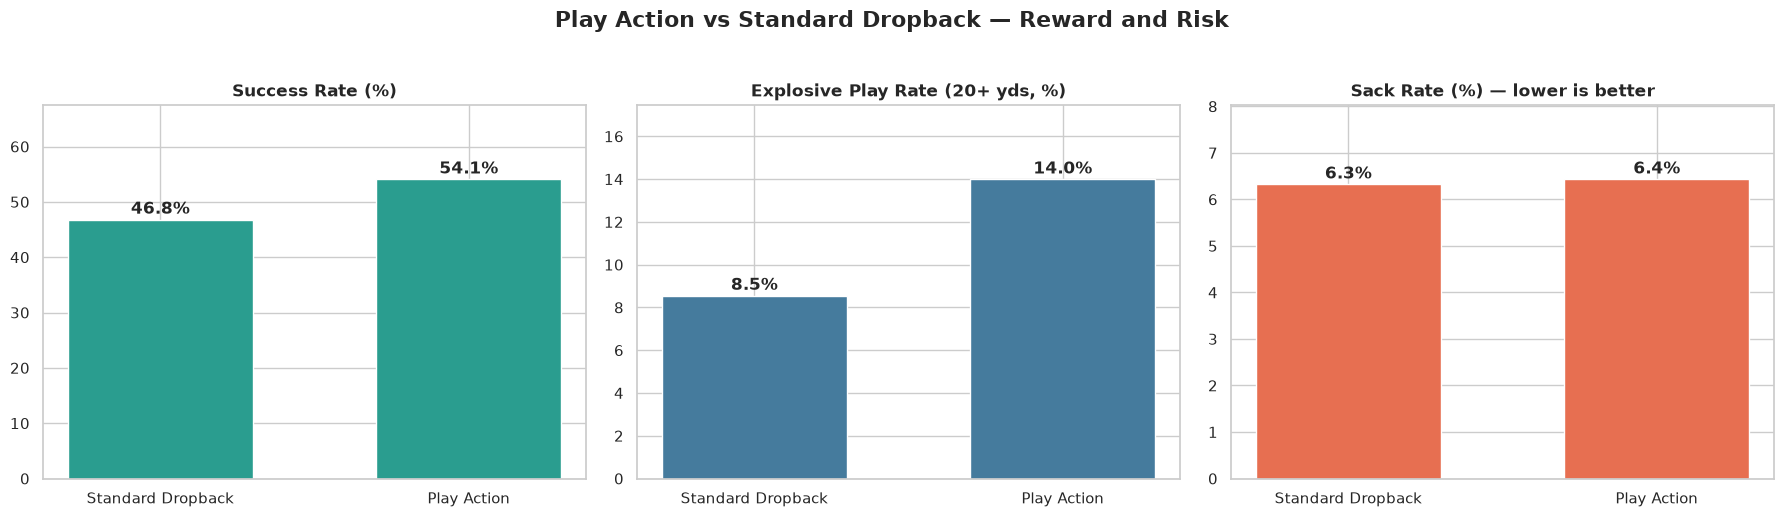

Play action success rate: 54.1%  vs standard: 46.8%  (diff +7.3 pts)
Play action sack rate:    6.4%  vs standard: 6.3%  (diff +0.1 pts)

💡 TAKEAWAY: compare the success/explosive gains against the change in sack risk above.


In [3]:
pa = plays.dropna(subset=['pff_playAction']).copy()
pa['label'] = pa['pff_playAction'].map({1: 'Play Action', 0: 'Standard Dropback'})

summary = pa.groupby('label').agg(
    success_rate=('success', lambda x: x.mean() * 100),
    explosive_rate=('is_explosive', lambda x: x.mean() * 100),
    sack_rate=('is_sack', lambda x: x.mean() * 100),
    avg_yards=('playResult', 'mean'),
    n=('success', 'count')
).reindex(['Standard Dropback', 'Play Action'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = [('success_rate', 'Success Rate (%)', '#2a9d8f', True),
           ('explosive_rate', 'Explosive Play Rate (20+ yds, %)', '#457b9d', True),
           ('sack_rate', 'Sack Rate (%) — lower is better', '#e76f51', False)]

for ax, (col, title, color, higher_better) in zip(axes, metrics):
    bars = ax.bar(summary.index, summary[col], color=color, edgecolor='white', width=0.6)
    for bar, v in zip(bars, summary[col]):
        ax.text(bar.get_x() + bar.get_width()/2, v + max(summary[col]) * 0.02,
                f'{v:.1f}%', ha='center', fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylim(0, max(summary[col]) * 1.25)

plt.suptitle('Play Action vs Standard Dropback — Reward and Risk', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

pa_sr = summary.loc['Play Action', 'success_rate']
std_sr = summary.loc['Standard Dropback', 'success_rate']
pa_sack = summary.loc['Play Action', 'sack_rate']
std_sack = summary.loc['Standard Dropback', 'sack_rate']
print(f'Play action success rate: {pa_sr:.1f}%  vs standard: {std_sr:.1f}%  (diff {pa_sr-std_sr:+.1f} pts)')
print(f'Play action sack rate:    {pa_sack:.1f}%  vs standard: {std_sack:.1f}%  (diff {pa_sack-std_sack:+.1f} pts)')
print('\n💡 TAKEAWAY: compare the success/explosive gains against the change in sack risk above.')

---
## 3 — Which formation gives the best results?

We rank formations by success rate, but show the *sample size* too — a formation used 20 times
isn't a trustworthy trend. A good recommendation needs both high success **and** enough usage.

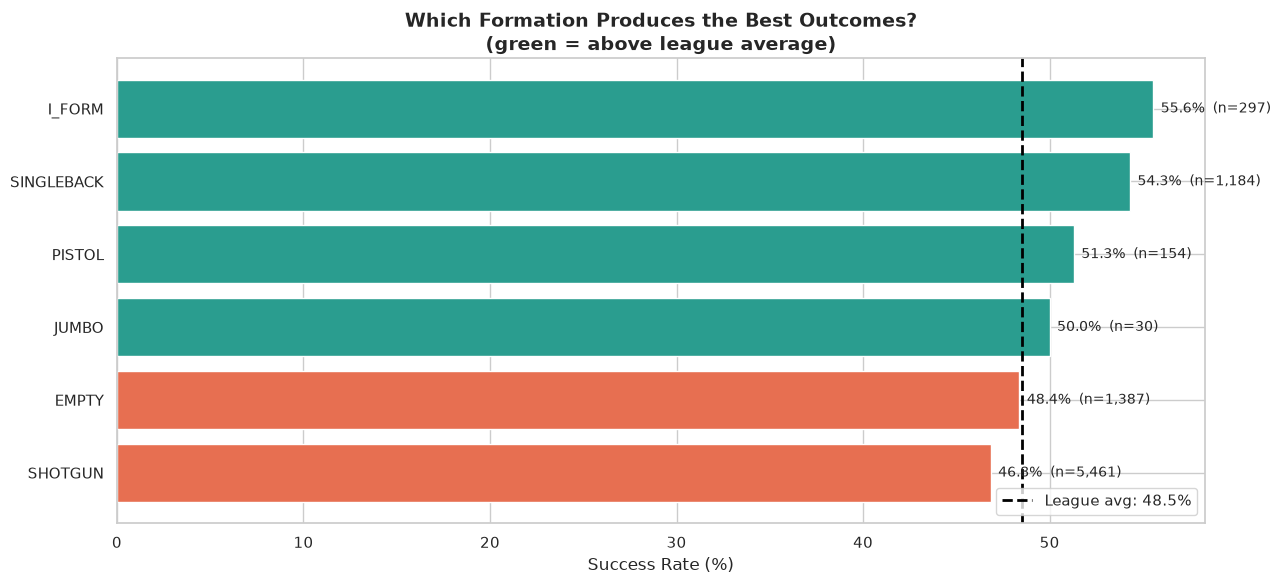

💡 Best reliable formation by success rate: I_FORM (55.6%, used 297 times)


In [4]:
form = plays.dropna(subset=['offenseFormation']).groupby('offenseFormation').agg(
    success_rate=('success', lambda x: x.mean() * 100),
    explosive_rate=('is_explosive', lambda x: x.mean() * 100),
    avg_yards=('playResult', 'mean'),
    n=('success', 'count')
).reset_index()
form = form[form['n'] >= 30].sort_values('success_rate', ascending=True)  # reliable sample only

fig, ax = plt.subplots(figsize=(13, 6))
league = plays['success'].mean() * 100
colors = ['#2a9d8f' if s > league else '#e76f51' for s in form['success_rate']]
bars = ax.barh(form['offenseFormation'], form['success_rate'], color=colors, edgecolor='white')
ax.axvline(league, color='black', linestyle='--', linewidth=2, label=f'League avg: {league:.1f}%')
for i, (s, n) in enumerate(zip(form['success_rate'], form['n'])):
    ax.text(s + 0.4, i, f'{s:.1f}%  (n={n:,})', va='center', fontsize=10)
ax.set_xlabel('Success Rate (%)', fontsize=12)
ax.set_title('Which Formation Produces the Best Outcomes?\n(green = above league average)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

best = form.sort_values('success_rate', ascending=False).iloc[0]
print(f'💡 Best reliable formation by success rate: {best["offenseFormation"]} '
      f'({best["success_rate"]:.1f}%, used {int(best["n"]):,} times)')

---
## 4 — Personnel groupings: how many WRs vs TEs?

> **Coaching basics:** Personnel means how many running backs (RB), tight ends (TE), and wide
> receivers (WR) are on the field. More WRs usually means spreading the defense out; more TEs means
> extra protection and run threat. Which mix wins through the air?

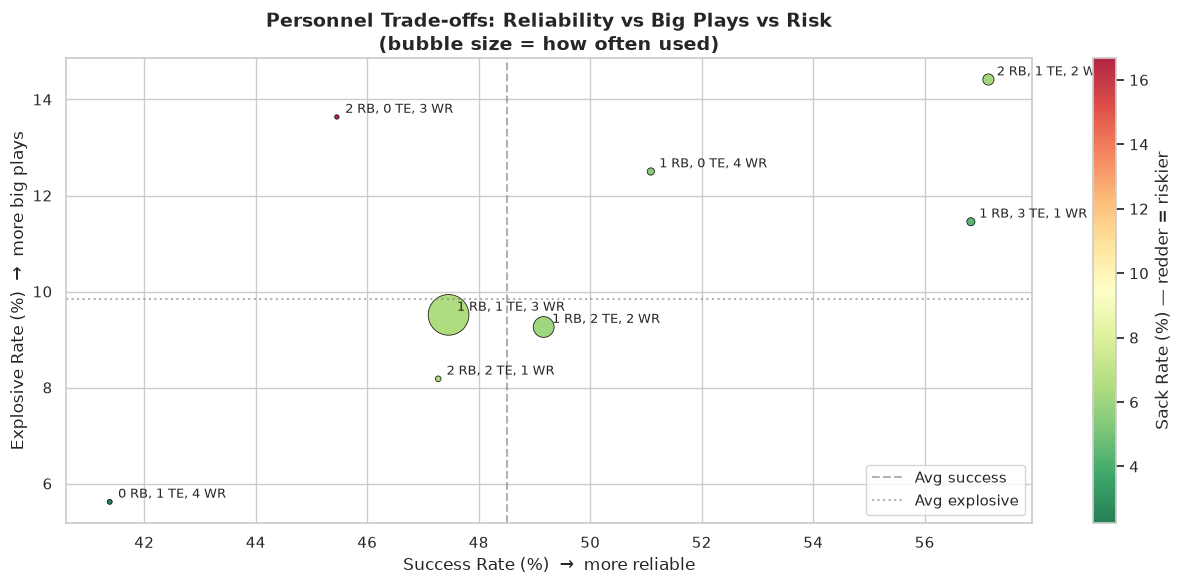

💡 Top-right bubbles with green color = reliable, explosive, AND safe. Those are the groupings to favor.


In [5]:
pers = plays.dropna(subset=['personnelO']).groupby('personnelO').agg(
    success_rate=('success', lambda x: x.mean() * 100),
    explosive_rate=('is_explosive', lambda x: x.mean() * 100),
    sack_rate=('is_sack', lambda x: x.mean() * 100),
    n=('success', 'count')
).reset_index()
pers = pers[pers['n'] >= 50].sort_values('success_rate', ascending=False)

fig, ax = plt.subplots(figsize=(13, 6))
scatter = ax.scatter(pers['success_rate'], pers['explosive_rate'],
                     s=pers['n'] * 0.15, c=pers['sack_rate'], cmap='RdYlGn_r',
                     edgecolors='black', linewidth=0.6, alpha=0.85)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Sack Rate (%) — redder = riskier')
for _, row in pers.iterrows():
    ax.annotate(row['personnelO'], (row['success_rate'], row['explosive_rate']),
                textcoords='offset points', xytext=(6, 3), fontsize=9)
ax.axvline(plays['success'].mean() * 100, color='gray', linestyle='--', alpha=0.6, label='Avg success')
ax.axhline(plays['is_explosive'].mean() * 100, color='gray', linestyle=':', alpha=0.6, label='Avg explosive')
ax.set_xlabel('Success Rate (%)  →  more reliable', fontsize=12)
ax.set_ylabel('Explosive Rate (%)  →  more big plays', fontsize=12)
ax.set_title('Personnel Trade-offs: Reliability vs Big Plays vs Risk\n(bubble size = how often used)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
print('💡 Top-right bubbles with green color = reliable, explosive, AND safe. Those are the groupings to favor.')

---
## 5 — Defense: which coverage gives up the least?

Now flip to the defensive side. For a defense, a "success" for the offense is a *bad* outcome — so the
best coverages have the **lowest** offensive success rate against them.

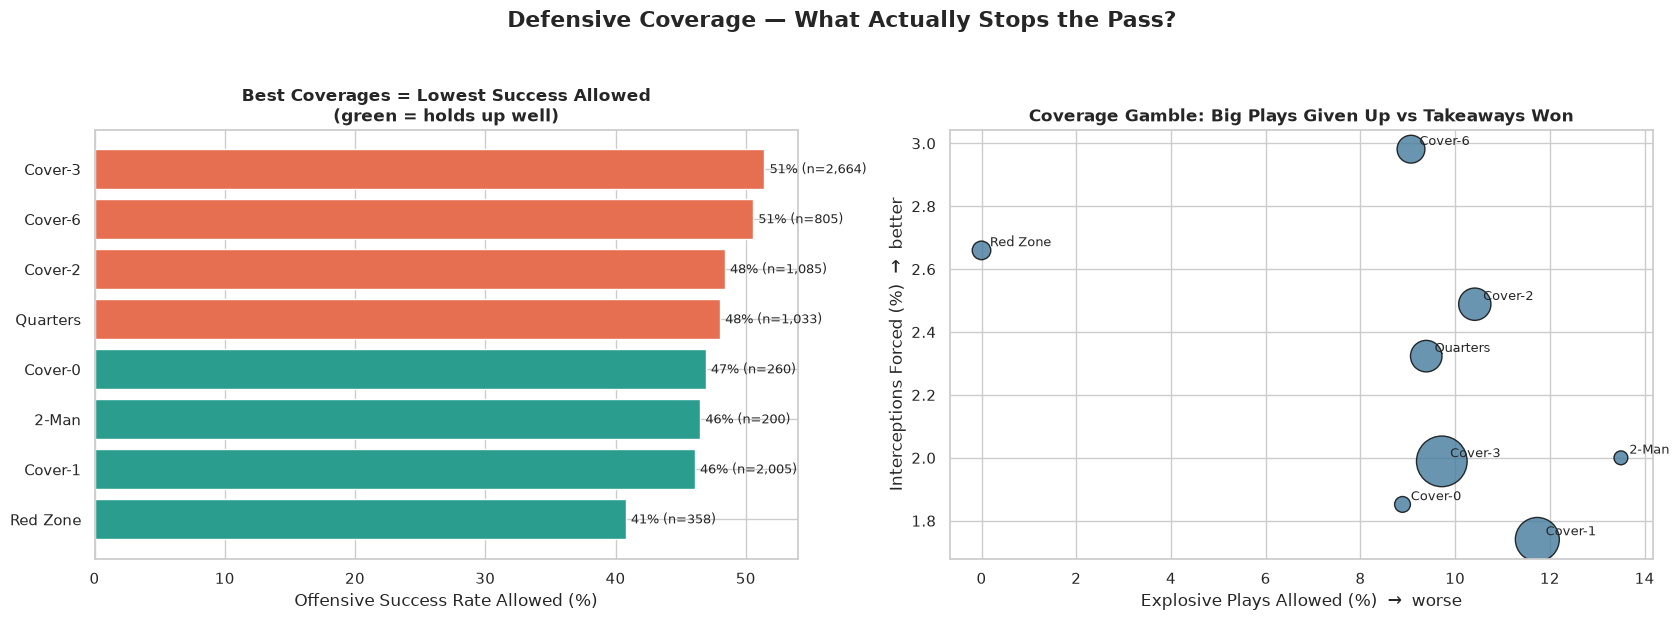

💡 Stingiest coverage: Red Zone (allows 41% success)
   Most exploited:    Cover-3 (allows 51% success)


In [6]:
cov = plays.dropna(subset=['pff_passCoverage']).groupby('pff_passCoverage').agg(
    off_success=('success', lambda x: x.mean() * 100),
    explosive_allowed=('is_explosive', lambda x: x.mean() * 100),
    int_rate=('is_int', lambda x: x.mean() * 100),
    n=('success', 'count')
).reset_index()
cov = cov[cov['n'] >= 80].sort_values('off_success', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Offensive success allowed (lower = better defense)
colors = ['#2a9d8f' if s < cov['off_success'].median() else '#e76f51' for s in cov['off_success']]
axes[0].barh(cov['pff_passCoverage'], cov['off_success'], color=colors, edgecolor='white')
for i, (s, n) in enumerate(zip(cov['off_success'], cov['n'])):
    axes[0].text(s + 0.4, i, f'{s:.0f}% (n={n:,})', va='center', fontsize=9)
axes[0].set_xlabel('Offensive Success Rate Allowed (%)')
axes[0].set_title('Best Coverages = Lowest Success Allowed\n(green = holds up well)',
                  fontsize=12, fontweight='bold')

# Risk/reward: explosive allowed vs interceptions forced
axes[1].scatter(cov['explosive_allowed'], cov['int_rate'], s=cov['n'] * 0.5,
                color='#457b9d', edgecolors='black', alpha=0.8)
for _, row in cov.iterrows():
    axes[1].annotate(row['pff_passCoverage'], (row['explosive_allowed'], row['int_rate']),
                     textcoords='offset points', xytext=(6, 3), fontsize=9)
axes[1].set_xlabel('Explosive Plays Allowed (%)  →  worse')
axes[1].set_ylabel('Interceptions Forced (%)  →  better')
axes[1].set_title('Coverage Gamble: Big Plays Given Up vs Takeaways Won', fontsize=12, fontweight='bold')

plt.suptitle('Defensive Coverage — What Actually Stops the Pass?', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

best_cov = cov.iloc[0]
worst_cov = cov.iloc[-1]
print(f'💡 Stingiest coverage: {best_cov["pff_passCoverage"]} (allows {best_cov["off_success"]:.0f}% success)')
print(f'   Most exploited:    {worst_cov["pff_passCoverage"]} (allows {worst_cov["off_success"]:.0f}% success)')

---
## 6 — The biggest lever: avoiding negative plays

> **Coaching basics:** Sacks and interceptions are drive-killers. One of the fastest ways for a team
> to "evolve" is simply to have fewer of them. Let's see how much a sack or INT swings the outcome,
> and in which situations they spike.

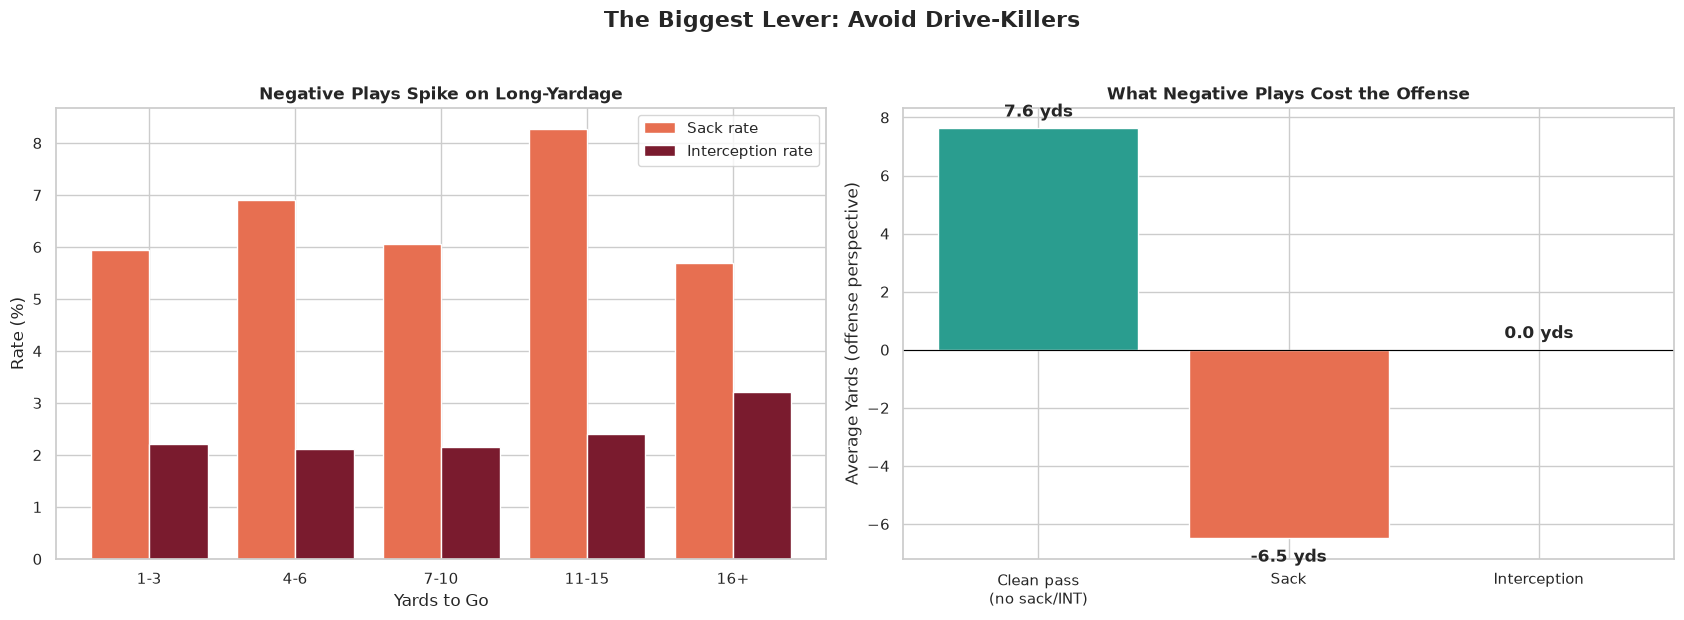

Overall sack rate: 6.3%  |  interception rate: 2.2%
💡 Staying out of long-yardage (16+) sharply cuts sack and INT risk — convert early downs!


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Sack rate by yards-to-go bucket (pressure builds on long-yardage)
plays['ytg_bucket'] = pd.cut(plays['yardsToGo'], bins=[0, 3, 6, 10, 15, 100],
                             labels=['1-3', '4-6', '7-10', '11-15', '16+'])
neg = plays.dropna(subset=['ytg_bucket']).groupby('ytg_bucket', observed=True).agg(
    sack_rate=('is_sack', lambda x: x.mean() * 100),
    int_rate=('is_int', lambda x: x.mean() * 100)
).reset_index()

x = np.arange(len(neg)); w = 0.4
axes[0].bar(x - w/2, neg['sack_rate'], w, label='Sack rate', color='#e76f51', edgecolor='white')
axes[0].bar(x + w/2, neg['int_rate'], w, label='Interception rate', color='#7a1b2e', edgecolor='white')
axes[0].set_xticks(x); axes[0].set_xticklabels(neg['ytg_bucket'])
axes[0].set_xlabel('Yards to Go'); axes[0].set_ylabel('Rate (%)')
axes[0].set_title('Negative Plays Spike on Long-Yardage', fontsize=12, fontweight='bold')
axes[0].legend()

# Success rate: clean play vs pressured (sack) vs turnover
buckets = {
    'Clean pass\n(no sack/INT)': plays[(plays['is_sack'] == 0) & (plays['is_int'] == 0)]['playResult'].mean(),
    'Sack': plays[plays['is_sack'] == 1]['playResult'].mean(),
    'Interception': plays[plays['is_int'] == 1]['playResult'].mean(),
}
colors_b = ['#2a9d8f', '#e76f51', '#7a1b2e']
bars = axes[1].bar(buckets.keys(), buckets.values(), color=colors_b, edgecolor='white')
axes[1].axhline(0, color='black', linewidth=0.8)
for bar, v in zip(bars, buckets.values()):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + (0.4 if v >= 0 else -0.8),
                 f'{v:.1f} yds', ha='center', fontweight='bold')
axes[1].set_ylabel('Average Yards (offense perspective)')
axes[1].set_title('What Negative Plays Cost the Offense', fontsize=12, fontweight='bold')

plt.suptitle('The Biggest Lever: Avoid Drive-Killers', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print(f'Overall sack rate: {plays["is_sack"].mean()*100:.1f}%  |  interception rate: {plays["is_int"].mean()*100:.1f}%')
print('💡 Staying out of long-yardage (16+) sharply cuts sack and INT risk — convert early downs!')

---
## 7 — The Data-Driven Playbook: a ranked list of recommendations

Finally, we combine everything into a single ranked chart: each *action* scored by how much its success
rate beats (or trails) the league average. Positive = "do more of this," negative = "use with caution."

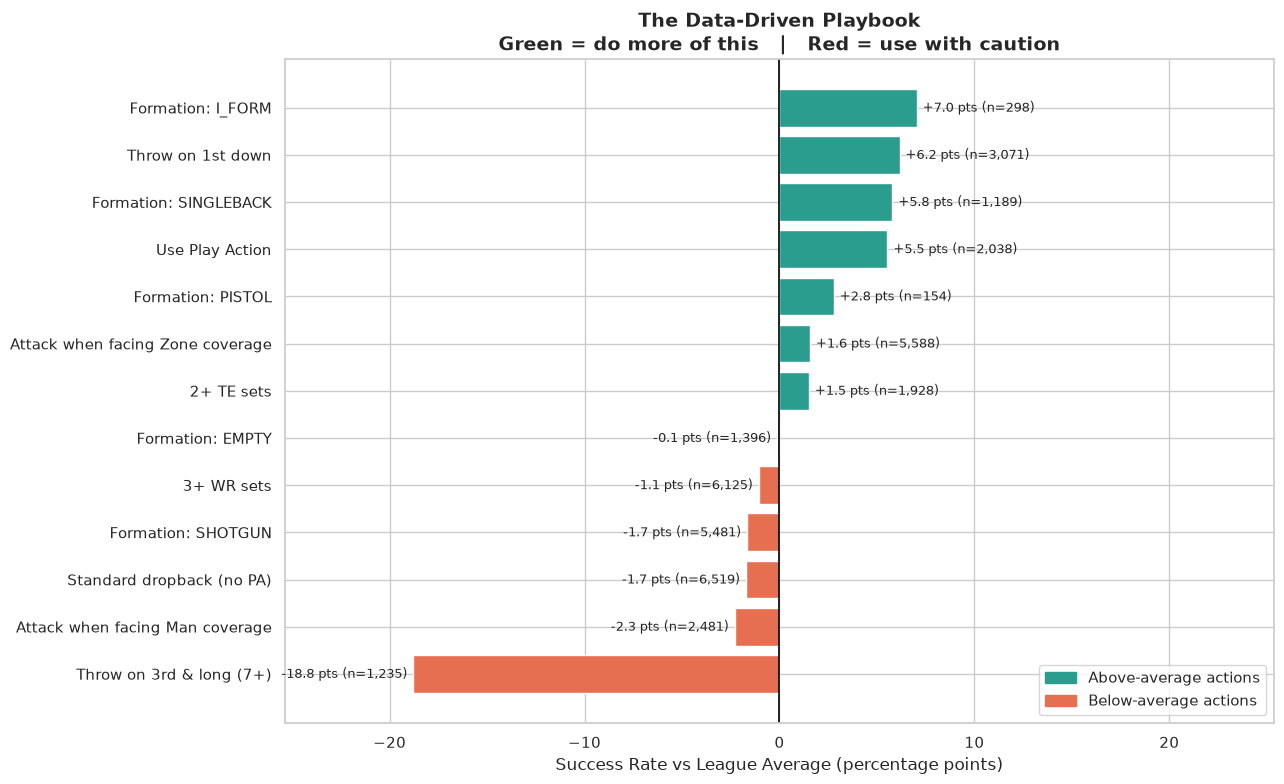

In [8]:
league = plays['success'].mean() * 100
recs = []

def add_rec(label, mask, min_n=50):
    sub = plays[mask]
    if len(sub) >= min_n:
        sr = sub['success'].mean() * 100
        recs.append((label, sr - league, len(sub)))

# Build a set of comparable actions
add_rec('Use Play Action', plays['pff_playAction'] == 1)
add_rec('Standard dropback (no PA)', plays['pff_playAction'] == 0)
for f in plays['offenseFormation'].dropna().unique():
    add_rec(f'Formation: {f}', plays['offenseFormation'] == f)
add_rec('3+ WR sets', plays['personnelO'].str.contains('3 WR|4 WR', na=False))
add_rec('2+ TE sets', plays['personnelO'].str.contains('2 TE|3 TE', na=False))
add_rec('Attack when facing Man coverage', plays['pff_passCoverageType'] == 'Man')
add_rec('Attack when facing Zone coverage', plays['pff_passCoverageType'] == 'Zone')
add_rec('Throw on 1st down', plays['down'] == 1)
add_rec('Throw on 3rd & long (7+)', (plays['down'] == 3) & (plays['yardsToGo'] >= 7))

rec_df = pd.DataFrame(recs, columns=['action', 'edge', 'n']).sort_values('edge')

fig, ax = plt.subplots(figsize=(13, 8))
colors = ['#2a9d8f' if e > 0 else '#e76f51' for e in rec_df['edge']]
bars = ax.barh(rec_df['action'], rec_df['edge'], color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=1.2)
xmax = rec_df['edge'].abs().max()
ax.set_xlim(-xmax * 1.35, xmax * 1.35)
for i, (e, n) in enumerate(zip(rec_df['edge'], rec_df['n'])):
    ax.text(e + (0.3 if e >= 0 else -0.3), i, f'{e:+.1f} pts (n={n:,})',
            va='center', ha='left' if e >= 0 else 'right', fontsize=9)
ax.set_xlabel('Success Rate vs League Average (percentage points)', fontsize=12)
ax.set_title('The Data-Driven Playbook\n'
             'Green = do more of this   |   Red = use with caution', fontsize=14, fontweight='bold')
grn = mpatches.Patch(color='#2a9d8f', label='Above-average actions')
red = mpatches.Patch(color='#e76f51', label='Below-average actions')
ax.legend(handles=[grn, red], loc='lower right')
plt.tight_layout()
plt.show()

---
## How to Play Better & Evolve — Summary

Reading the playbook chart above, the data points to a clear game plan:

1. **Measure the right thing.** Track *success rate*, not just yards. A 4-yard gain can be a win or a loss
   depending on the situation.
2. **Win early downs.** Success on 1st and 2nd down keeps you out of 3rd-and-long, where sack and
   interception risk spikes. This is the single biggest lever.
3. **Favor your highest-success formations and personnel** — but only the ones with enough usage to trust.
   Chase the top-right, green bubbles (reliable + explosive + safe).
4. **Protect the ball.** Sacks and interceptions are drive-killers worth several yards each. Cutting them
   is often faster to fix than adding big plays.
5. **On defense, pick your gamble.** Aggressive man coverages can force takeaways but give up explosives;
   zone coverages are steadier. Match the scheme to the game situation.

### How a team "evolves"
> Great teams don't just run more plays — they **shift their play-mix toward their highest-success actions**
> and **cut their lowest-success ones**. Re-running this notebook week over week shows whether a team is
> trending the right way.